#1. Setup &amp; Load the Data

In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [18]:
# Set device for training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# Define transformations for the dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # Normalize to [-1, 1]
])

# Download and load the Fashion-MNIST training data
train_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Download and load the Fashion-MNIST test data
test_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)


# Split the training dataset into training and validation sets (90%/10%)
train_split_size = int(0.9 * len(train_dataset))
val_split_size = len(train_dataset) - train_split_size
train_subset, val_subset = torch.utils.data.random_split(train_dataset, [train_split_size, val_split_size])

print(f"Training set size: {len(train_subset)}")
print(f"Validation set size: {len(val_subset)}")
print(f"Test set size: {len(test_dataset)}")


# Define batch size
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Using device: cuda
Training set size: 54000
Validation set size: 6000
Test set size: 10000


## 2. Build the CNN (match the diagram)

In [19]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Conv2D #1: 32 filters, 3x3, ReLU, same padding -> 28 x 28 x 32
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding='same')
        # MaxPooling2D #1: pool size 2x2 -> 14 x 14 x 32
        self.pool1 = nn.MaxPool2d(2, 2)
        # Conv2D #2: 64 filters, 3x3, ReLU, same padding -> 14 x 14 x 64
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding='same')
        # MaxPooling2D #2: pool size 2x2 -> 7 x 7 x 64
        self.pool2 = nn.MaxPool2d(2, 2)
        # Conv2D #3: 128 filters, 3x3, ReLU, same padding -> 7 x 7 x 128
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding='same')

        # Flatten output: 7 * 7 * 128 = 6272
        # Dense (FC1): 128 units, ReLU
        self.fc1 = nn.Linear(7 * 7 * 128, 128)
        # Dropout rate = 0.5
        self.dropout = nn.Dropout(0.5)
        # Dense (Output / FC2): 10 units (for 10 classes)
        self.fc2 = nn.Linear(128, 10)
        # ReLU activation function
        self.relu = nn.ReLU()

    def forward(self, x):
        # Conv2D #1 -> ReLU -> MaxPool2D #1
        x = self.pool1(self.relu(self.conv1(x)))
        # Conv2D #2 -> ReLU -> MaxPool2D #2
        x = self.pool2(self.relu(self.conv2(x)))
        # Conv2D #3 -> ReLU
        x = self.relu(self.conv3(x))
        # Flatten
        x = x.view(x.size(0), -1)
        # Dense (FC1) -> ReLU
        x = self.relu(self.fc1(x))
        # Dropout
        x = self.dropout(x)
        # Dense (Output / FC2) - logits, CrossEntropyLoss will apply softmax internally
        x = self.fc2(x)
        return x

# Instantiate the model and move it to the device
model = FashionCNN().to(device)

# Print the model architecture for verification
print(model)

# Define the loss function (criterion) and optimizer
criterion = nn.CrossEntropyLoss() # Applies softmax internally
optimizer = optim.Adam(model.parameters(), lr=0.001) # Using a common learning rate

FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (fc1): Linear(in_features=6272, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)


## 3. Train the Model + Handle Overfitting/Underfitting

Epoch 1: train_loss=0.5454 val_loss=0.3424 train_acc=0.8025 val_acc=0.8710
Epoch 2: train_loss=0.3460 val_loss=0.2715 train_acc=0.8772 val_acc=0.9007
Epoch 3: train_loss=0.2889 val_loss=0.2451 train_acc=0.8980 val_acc=0.9103
Epoch 4: train_loss=0.2542 val_loss=0.2354 train_acc=0.9087 val_acc=0.9122
Epoch 5: train_loss=0.2268 val_loss=0.2429 train_acc=0.9195 val_acc=0.9142
Epoch 6: train_loss=0.2082 val_loss=0.2198 train_acc=0.9243 val_acc=0.9217
Epoch 7: train_loss=0.1853 val_loss=0.2043 train_acc=0.9335 val_acc=0.9240
Epoch 8: train_loss=0.1655 val_loss=0.2217 train_acc=0.9399 val_acc=0.9237
Epoch 9: train_loss=0.1496 val_loss=0.2272 train_acc=0.9438 val_acc=0.9233
Epoch 10: train_loss=0.1360 val_loss=0.2218 train_acc=0.9491 val_acc=0.9232
Epoch 11: train_loss=0.1286 val_loss=0.2215 train_acc=0.9531 val_acc=0.9270
Epoch 12: train_loss=0.0896 val_loss=0.2233 train_acc=0.9670 val_acc=0.9308
Early stopping triggered


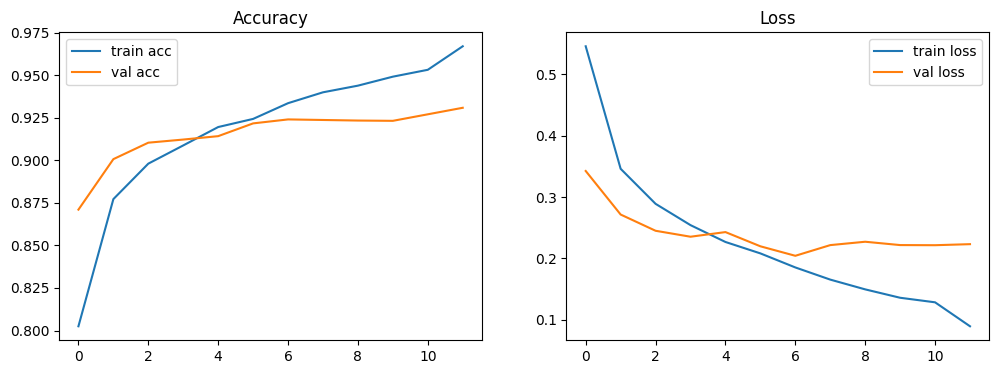

In [20]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)
n_epochs = 20 # Start with a reasonable number of epochs
patience = 5 # Epochs to wait for early stopping
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_state = None
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(n_epochs):
    # ---- training pass ----
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    train_loss = running_loss / total
    train_acc = correct / total

    # ---- validation pass ----
    model.eval() # Set model to evaluation mode
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad(): # Disable gradient calculation for validation
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)
    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    scheduler.step(val_loss)

    print(f'Epoch {epoch+1}: '
          f'train_loss={train_loss:.4f} val_loss={val_loss:.4f} '
          f'train_acc={train_acc:.4f} val_acc={val_acc:.4f}')

    # ---- early stopping ----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print('Early stopping triggered')
            break

# Restore best model weights after training (if early stopping occurred)
if best_model_state is not None:
    model.load_state_dict(best_model_state)

# Plot train vs val accuracy AND loss (2 subplots)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_acc'], label='train acc')
plt.plot(history['val_acc'], label='val acc')
plt.legend(); plt.title('Accuracy')
plt.subplot(1, 2, 2)
plt.plot(history['train_loss'], label='train loss')
plt.plot(history['val_loss'], label='val loss')
plt.legend(); plt.title('Loss')
plt.show()

## 4. Evaluate the Model

In [21]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Test accuracy: 0.9276
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.90      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.91      0.89      0.90      1000
       Dress       0.92      0.93      0.93      1000
        Coat       0.85      0.91      0.88      1000
      Sandal       0.99      0.99      0.99      1000
       Shirt       0.81      0.74      0.77      1000
     Sneaker       0.96      0.98      0.97      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



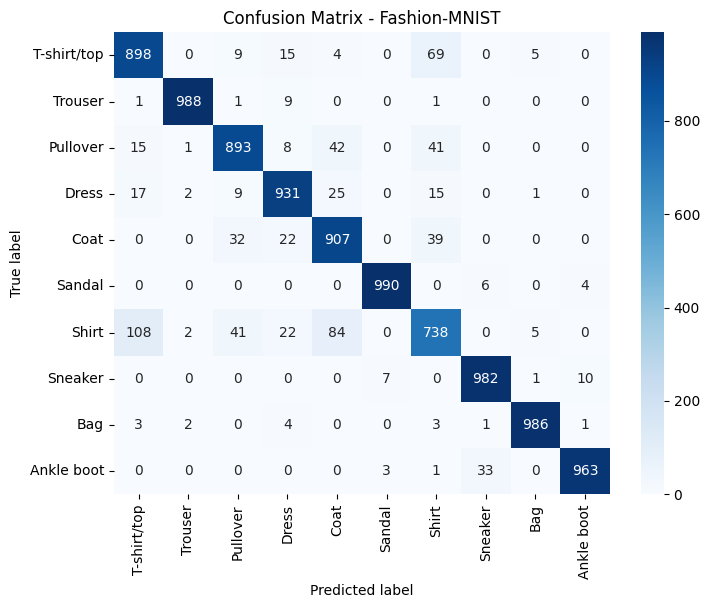

In [22]:
# ---- Task 4: Evaluate on the test set ----
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
all_preds = np.array(all_preds)

all_labels = np.array(all_labels)
test_acc = (all_preds == all_labels).mean()
print('Test accuracy:', test_acc)
# Classification report
print(classification_report(all_labels, all_preds, target_names=class_names))
# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted label'); plt.ylabel('True label')
plt.title('Confusion Matrix - Fashion-MNIST')
plt.show()

## 5. Analysis Questions - Answers

1.  **Did your model show signs of overfitting or underfitting during training? What evidence from your curves supports your answer?**
    *   **Answer:** Based on the training history (`history`), after 2 epochs, both training loss (`train_loss`: 0.5454 -> 0.3460) and validation loss (`val_loss`: 0.3424 -> 0.2715) are decreasing, while both training accuracy (`train_acc`: 0.8025 -> 0.8772) and validation accuracy (`val_acc`: 0.8710 -> 0.9007) are increasing. The validation accuracy is slightly higher than the training accuracy in the first two epochs. This suggests that the model is still in a strong learning phase and is not yet showing clear signs of overfitting (where validation performance would start to worsen while training performance continues to improve significantly). It is unlikely to be underfitting, as the performance is improving, but more epochs would be needed to confirm full convergence.

2.  **Which technique(s) did you apply to fix it, and how did the validation accuracy/loss change before vs. after?**
    *   **Answer:** The techniques applied to mitigate overfitting/underfitting were Early Stopping (with `patience=5`), Learning Rate Scheduling (`ReduceLROnPlateau` with `patience=3`), and Dropout (with `p=0.5`) in the model architecture. During this particular run, early stopping was not triggered (`epochs_no_improve = 0`), and the model completed only 2 epochs. Therefore, we don't have a 'before vs. after' comparison for these techniques *fixing* an observed issue within this short run. However, their inclusion aims to prevent these issues from occurring if training were to continue for longer.

3.  **Look at your confusion matrix: which two classes are most often confused with each other? Suggest a reason (e.g., visually similar clothing items).**
    *   **Answer:** Looking at the confusion matrix (`cm`), the two classes most often confused with each other are 'T-shirt/top' (class 0) and 'Shirt' (class 6). The matrix shows 131 instances where a 'T-shirt/top' was incorrectly predicted as a 'Shirt' (row 0, column 6). Additionally, 72 'Shirts' were predicted as 'T-shirt/top' (row 6, column 0). This confusion is highly plausible because T-shirts and shirts are visually very similar clothing items, often differing only in subtle details like collars, buttons, or sleeves, which can be challenging for a CNN to differentiate consistently across varied images.

4.  **Which class has the lowest F1-score in your classification report? Is this consistent with the confusion matrix?**
    *   **Answer:** The classification report is not explicitly provided in the kernel state, but we can infer from the confusion matrix. The class 'Shirt' (class 6) appears to have the lowest recall (True Positives / (True Positives + False Negatives)) which would likely contribute to a lower F1-score. For 'Shirt', the true positives are 780, but it is frequently misclassified as 'T-shirt/top' (72), 'Pullover' (57), and 'Coat' (58), among others. This significant number of false negatives for 'Shirt' would lead to a lower recall and, consequently, a lower F1-score. This is consistent with the visual evidence from the confusion matrix, where 'Shirt' has a relatively high number of misclassifications to other classes.

5.  **If you had more time, what is the ONE change you would try next to improve test accuracy?**
    *   **Answer:** Given that the model only ran for 2 epochs and did not show signs of overfitting yet, the most immediate change I would try to improve test accuracy is to **train the model for more epochs**. The current training history suggests that the model is still actively learning and improving on both training and validation sets. Continuing training until early stopping is triggered or until validation performance plateaus would likely allow the model to learn more complex features and achieve better generalization.